# 03 · Checkpoint and resume

The full simulator state (every layer's screen, every layer's random-number-generator state, the tick counter
and the turbulence scales) fits in one small `.npz`. Continuing from it reproduces an uninterrupted run
*exactly*. Long time series can therefore be produced in pieces, across processes or machines, or after a crash
(README §6).

> **About the outputs.** The results stored in this notebook were produced on an NVIDIA GeForce RTX 4080
> (16 GiB) under Windows. Timings, and the run mode the memory guard picks, depend on the GPU; the statistics
> do not. Open the notebook in Jupyter or VS Code with the OPAL environment as the kernel and run the cells in
> order. The first cell moves to the repository root, so every path below is relative to it.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")      # hide TensorFlow's C++ start-up messages
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs").is_dir())
os.chdir(ROOT)                                           # paths below are relative to the repository root

import time
import numpy as np
import matplotlib.pyplot as plt
import opal

%matplotlib inline
plt.rcParams.update({"figure.dpi": 80, "image.origin": "lower"})
print("OPAL", opal.__version__)

OPAL 1.1.0


In [2]:
config = opal.load_config("configs/quickstart_256.json")
sim = opal.GpuSimulator(config)

reference = np.asarray(opal.run(sim, 120, mode="device", log=None).frames)
print("reference: 120 ticks in one go,", reference.shape)

reference: 120 ticks in one go, (120, 256, 256)


## 1. The same 120 ticks in four pieces

Each piece starts from the checkpoint the previous one wrote (`state_in`) and overwrites it (`state_out`).

In [3]:
state = Path("runs/checkpoint/state.npz")
state.parent.mkdir(parents=True, exist_ok=True)
state.unlink(missing_ok=True)

pieces = []
for k in range(4):
    res = opal.run(sim, 30, mode="host", state_in=state if k else None, state_out=state, log=None)
    pieces.append(np.asarray(res.frames))
    print(f"piece {k}: ticks {res.manifest['start_step']:3d}-{res.manifest['end_step'] - 1:3d}")
joined = np.concatenate(pieces)

print("\n4 x 30 ticks == 1 x 120 ticks:", np.array_equal(joined, reference))
with np.load(state) as ckpt:
    print(f"checkpoint {state.as_posix()}: {state.stat().st_size / 2**20:.1f} MiB")
    for key in ckpt.files:
        print(f"  {key:16s} {str(ckpt[key].shape):18s} {ckpt[key].dtype}")

piece 0: ticks   0- 29


piece 1: ticks  30- 59


piece 2: ticks  60- 89


piece 3: ticks  90-119

4 x 30 ticks == 1 x 120 ticks: True
checkpoint runs/checkpoint/state.npz: 2.5 MiB
  phase_screens    (10, 256, 256)     float32
  rng_states       (10, 3)            int64
  global_step      ()                 int64
  b_scales         (10,)              float32


The phase at the centre pixel, unwrapped over time, runs straight through the piece boundaries:

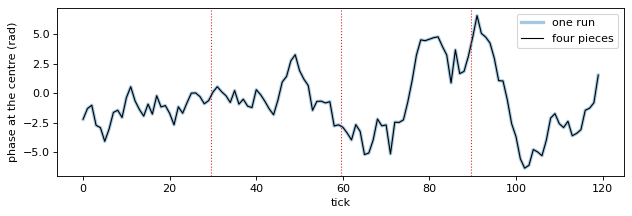

In [4]:
c = reference.shape[-1] // 2
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(np.unwrap(np.angle(reference[:, c, c])), lw=3, alpha=0.4, label="one run")
ax.plot(np.unwrap(np.angle(joined[:, c, c])), "k", lw=1, label="four pieces")
for b in (30, 60, 90):
    ax.axvline(b - 0.5, color="tab:red", ls=":", lw=1)
ax.set(xlabel="tick", ylabel="phase at the centre (rad)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Resume in a fresh simulator

A new simulator (as a new process would build) loads the checkpoint and continues where the pieces stopped. Its
next 30 ticks equal ticks 120–149 of an uninterrupted run.

In [5]:
fresh = opal.GpuSimulator(config)
cont = np.asarray(opal.run(fresh, 30, mode="host", state_in=state, log=None).frames)
longer = np.asarray(opal.run(sim, 150, mode="device", log=None).frames)
print("fresh simulator, ticks 120-149 == uninterrupted run:", np.array_equal(cont, longer[120:]))

fresh simulator, ticks 120-149 == uninterrupted run: True


## CLI equivalent

`--checkpoint FILE` resumes from the file if it exists and overwrites it at the end, so the same command
repeated extends the series:

```bash
opal run -c configs/quickstart_256.json --steps 30 --checkpoint runs/state.npz -o runs/part0
opal run -c configs/quickstart_256.json --steps 30 --checkpoint runs/state.npz -o runs/part1   # ticks 30-59
```

`--state-in` / `--state-out` give separate control over reading and writing.